# **Introduction**


Online payment is the most popular transaction method in the world today. However, with a rise in the online payments there is a drastic increase in online frauds. The objective of this study is to identify fraudulent and non-fraudulent payments. The dataset is collected from Kaggle, which contains historical information about fraudulent transactions which can be used to detect fraud in online payments.

The dataset consists of 10 variables:

* step: represents a unit of time where 1 step equals 1 hour
* type: type of online transaction
* amount: the amount of the transaction
* nameOrig: customer starting the transaction
* oldbalanceOrg: balance before the transaction
* newbalanceOrig: balance after the transaction
* nameDest: recipient of the transaction
* oldbalanceDest: initial balance of recipient before the transaction
* newbalanceDest: the new balance of recipient after the transaction
* isFraud: fraud transaction


# **Importing Dataset**

In [1]:




import warnings, copy
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
from tabulate import tabulate
from plotly.subplots import make_subplots
from plotly.offline import plot, iplot, init_notebook_mode
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency 
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics import classification_report, roc_curve, auc, ConfusionMatrixDisplay
init_notebook_mode(connected=True)
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
onlinefraud = pd.read_csv("onlinefraud.csv")
print(onlinefraud.head())


   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  


The dataset contains of 63,62,620 observations.

# **Analysing Dataset**

There are no missing values in the dataset.

In [2]:
fraud_min_max = [
    ['amount', onlinefraud.amount.min(), onlinefraud.amount.max()],
    ['oldbalanceOrg', onlinefraud.oldbalanceOrg.min(), onlinefraud.oldbalanceOrg.max()],
    ['newbalanceOrig', onlinefraud.newbalanceOrig.min(), onlinefraud.newbalanceOrig.max()],
    ['oldbalanceDest', onlinefraud.oldbalanceDest.min(), onlinefraud.oldbalanceDest.max()],
    ['isFraud', onlinefraud.isFraud.min(), onlinefraud.isFraud.max()]
] 

print(
    tabulate(
        fraud_min_max,
        headers=['columns', 'min value', 'max value'],
        showindex=True,
        tablefmt='orgtbl',
        numalign='right'
    )
)

|    | columns        |   min value |   max value |
|----+----------------+-------------+-------------|
|  0 | amount         |           0 | 9.24455e+07 |
|  1 | oldbalanceOrg  |           0 |  5.9585e+07 |
|  2 | newbalanceOrig |           0 |  4.9585e+07 |
|  3 | oldbalanceDest |           0 | 3.56016e+08 |
|  4 | isFraud        |           0 |           1 |


In [3]:
# Downcast numerical columns with smaller dtype

df = onlinefraud
for col in onlinefraud.columns:
    if df[col].dtype == 'float64':
        df[col] = pd.to_numeric(df[col], downcast='float')
    if df[col].dtype == 'int64':
        df[col] = pd.to_numeric(df[col], downcast='unsigned')

# Use category dtype for categorical column
df['type'] = df['type'].astype('category')

In [4]:

# Check duplicate values
df.duplicated().sum()

0

In [7]:
# Assuming 'data' is your DataFrame and 'isfraud' is the column you want to drop
X = df.drop('isFraud', axis=1)
y = df['isFraud']



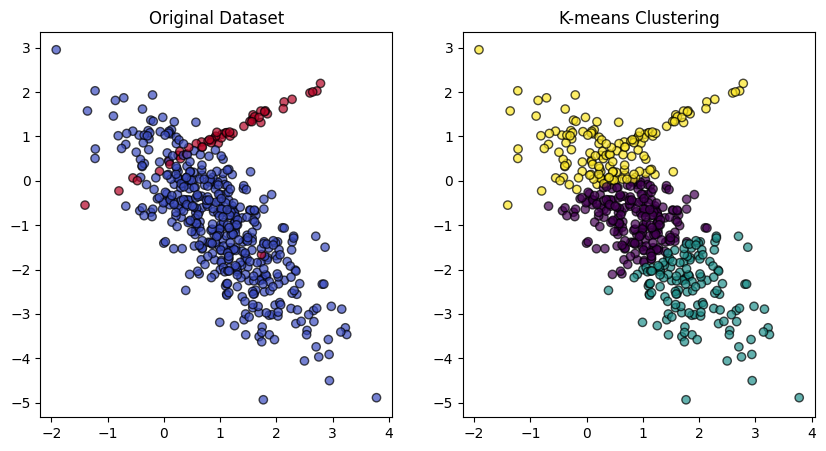

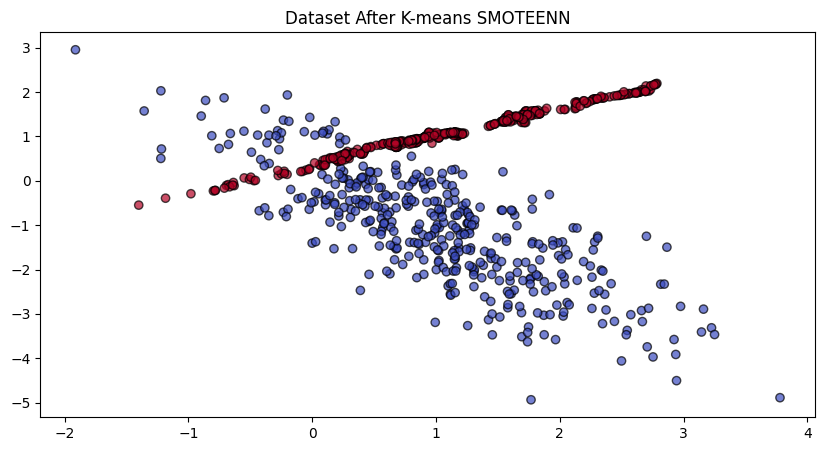

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE
from sklearn.cluster import KMeans

# Generate imbalanced dataset
X, y = make_classification(
    n_samples=500, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, weights=[0.9, 0.1], random_state=42
)

# Apply K-means Clustering
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X)

# Visualize original dataset with clusters
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', alpha=0.7)
plt.title("Original Dataset")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis', edgecolor='k', alpha=0.7)
plt.title("K-means Clustering")
plt.show()

# Apply SMOTEENN
smoteenn = SMOTEENN(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smoteenn.fit_resample(X, y)

# Visualize the resampled dataset
plt.figure(figsize=(10, 5))
plt.scatter(X_resampled[:, 0], X_resampled[:, 1], c=y_resampled, cmap='coolwarm', edgecolor='k', alpha=0.7)
plt.title("Dataset After K-means SMOTEENN")
plt.show()


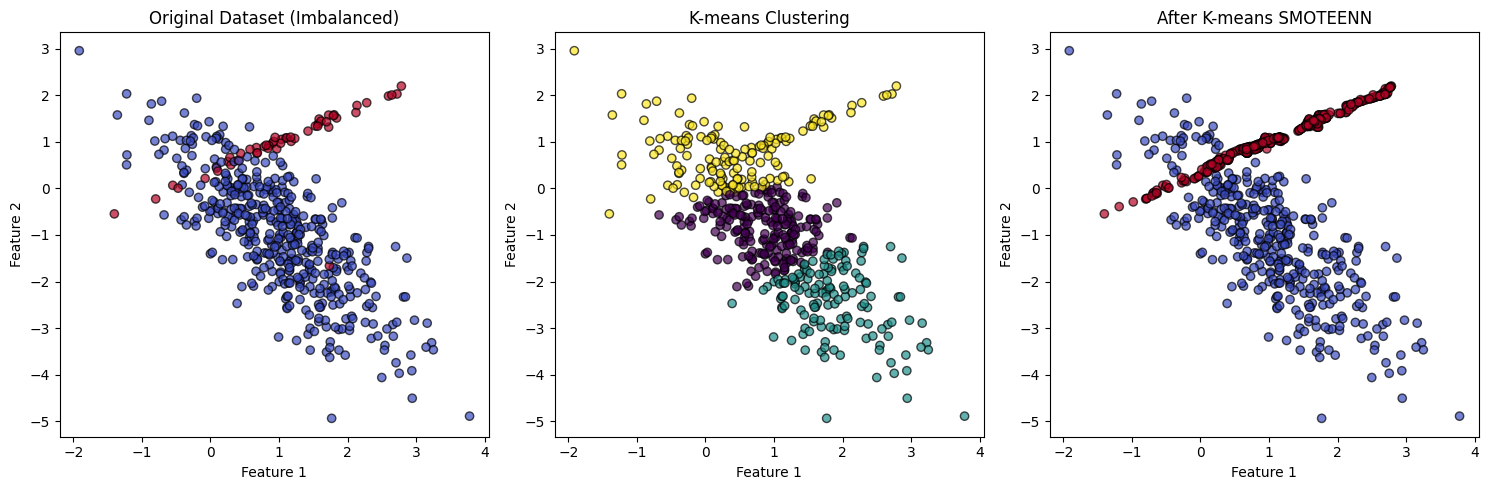

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.cluster import KMeans
from imblearn.combine import SMOTEENN

# Generating an imbalanced dataset
X, y = make_classification(
    n_samples=500, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, weights=[0.9, 0.1], random_state=42
)

# Applying K-means Clustering
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X)

# Plotting original dataset with clusters
plt.figure(figsize=(15, 5))

# Original dataset
plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', alpha=0.7)
plt.title("Original Dataset (Imbalanced)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# K-means clustering
plt.subplot(1, 3, 2)
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis', edgecolor='k', alpha=0.7)
plt.title("K-means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Applying SMOTEENN
smoteenn = SMOTEENN(random_state=42)
X_resampled, y_resampled = smoteenn.fit_resample(X, y)

# Resampled dataset
plt.subplot(1, 3, 3)
plt.scatter(X_resampled[:, 0], X_resampled[:, 1], c=y_resampled, cmap='coolwarm', edgecolor='k', alpha=0.7)
plt.title("After K-means SMOTEENN")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Displaying the plots
plt.tight_layout()
plt.show()
